<a href="https://colab.research.google.com/github/asnapareeth004-hue/traffic-congestion-prediction/blob/main/02_lstm_traffic_imputation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Option A: Upload the CSV from your computer
from google.colab import files
uploaded = files.upload()

file_path = next(iter(uploaded))
df = pd.read_csv(file_path)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c != "timestamp"]
traffic = df[sensor_cols].apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", traffic.shape)
print("Missing values:", traffic.isna().sum().sum())

Saving metr-la.csv to metr-la.csv
Dataset shape: (34272, 207)
Missing values: 0


In [2]:
# Set True only if zero readings are confirmed to mean missing data.
ZERO_IS_MISSING = True

if ZERO_IS_MISSING:
    traffic = traffic.mask(traffic == 0)

values = traffic.to_numpy(dtype=np.float32)

n = len(values)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_raw = values[:train_end]
val_raw = values[train_end:val_end]
test_raw = values[val_end:]

mean = np.nanmean(train_raw, axis=0)
std = np.nanstd(train_raw, axis=0)

mean = np.where(np.isfinite(mean), mean, 0.0)
std = np.where(np.isfinite(std) & (std > 1e-6), std, 1.0)

def scale_data(x):
    return (x - mean) / std

train = scale_data(train_raw)
val = scale_data(val_raw)
test = scale_data(test_raw)

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (23990, 207)
Validation: (5141, 207)
Test: (5141, 207)


In [3]:
WINDOW = 12
STRIDE = 6
MASK_RATE = 0.15
n_sensors = len(sensor_cols)

def prepare_data(data, seed=42):
    rng = np.random.default_rng(seed)

    sequences = np.array([
        data[i:i + WINDOW]
        for i in range(0, len(data) - WINDOW + 1, STRIDE)
    ], dtype=np.float32)

    observed = np.isfinite(sequences)
    artificial_mask = (
        (rng.random(sequences.shape) < MASK_RATE) & observed
    )

    corrupted = sequences.copy()
    corrupted[artificial_mask] = np.nan

    inputs = np.concatenate([
        np.nan_to_num(corrupted, nan=0.0),
        np.isfinite(corrupted).astype(np.float32)
    ], axis=-1)

    targets = np.concatenate([
        np.nan_to_num(sequences, nan=0.0),
        artificial_mask.astype(np.float32)
    ], axis=-1)

    return inputs, targets

X_train, y_train = prepare_data(train, seed=42)
X_val, y_val = prepare_data(val, seed=43)
X_test, y_test = prepare_data(test, seed=44)

print("Training input:", X_train.shape)

Training input: (3997, 12, 414)


In [4]:
inputs = tf.keras.Input(shape=(WINDOW, 2 * n_sensors))

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(64, return_sequences=True)
)(inputs)

x = tf.keras.layers.Dropout(0.2)(x)

x = tf.keras.layers.LSTM(32, return_sequences=True)(x)

outputs = tf.keras.layers.Dense(n_sensors)(x)

model = tf.keras.Model(inputs, outputs)

def masked_mse(y_true, y_pred):
    target = y_true[..., :n_sensors]
    mask = y_true[..., n_sensors:]

    return tf.reduce_sum(
        tf.square(target - y_pred) * mask
    ) / (tf.reduce_sum(mask) + 1e-8)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=masked_mse
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 414)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 12, 128)        │       245,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 12, 32)         │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12, 207)        │         6,831 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272,687 (1.04 MB)

 Trainable params: 272,687 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - loss: 0.7061 - val_loss: 0.6254
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.5241 - val_loss: 0.5594
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - loss: 0.4803 - val_loss: 0.5254
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - loss: 0.4549 - val_loss: 0.5040
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: 0.4362 - val_loss: 0.4891
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.4205 - val_loss: 0.4760
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.4086 - val_loss: 0.4661
Epoch 8/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.3981 - val_loss: 0.4572
Epoch 9/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - loss: 0.3898 - val_loss: 0.4492
Epoch 10/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.3821 - val_loss: 0.4420
Epoch 11/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - loss: 0.3755 - val_loss: 0.4385
Epoch 12/30
125/125 ━━━━━━━━━━━━━━━━━━━

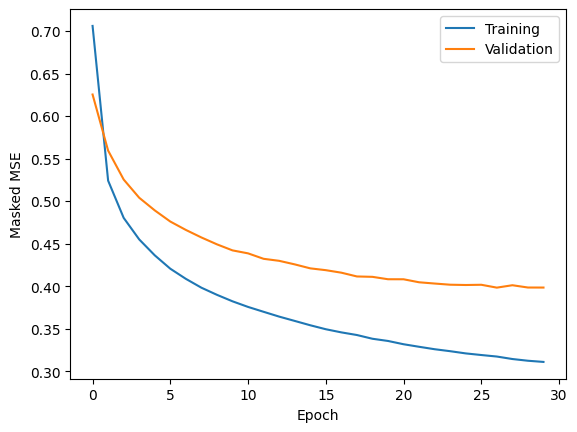

In [5]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.legend()
plt.show()

In [6]:
pred_scaled = model.predict(X_test)

true_scaled = y_test[..., :n_sensors]
test_mask = y_test[..., n_sensors:] > 0.5

true_values = true_scaled * std + mean
pred_values = pred_scaled * std + mean

y_true = true_values[test_mask]
y_pred = pred_values[test_mask]

if len(y_true) > 0:
    print("MAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
else:
    print("No artificially masked test readings were generated.")

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
MAE: 3.556788206100464
RMSE: 5.888847426902312


In [7]:
model.save("lstm_traffic_imputation.keras")